# Phân loại cảm xúc review phim IMDB

Bài thực nghiệm so sánh Logistic Regression, SVM, mạng truyền thẳng MLP, SimpleRNN và LSTM. Nhãn 0 là tiêu cực, nhãn 1 là tích cực.

Dùng 20.000 review để huấn luyện, 5.000 review để chọn epoch và 25.000 review để đánh giá. Các mô hình dùng cùng cách chia dữ liệu. SVM, Logistic Regression và MLP nhận đầu vào TF-IDF; RNN và LSTM nhận chuỗi ID từ.


## 1. Thiết lập

Cố định seed = 42 để giữ cách chia dữ liệu và khởi tạo mô hình.

In [1]:
import copy
import html
import random
import re
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from datasets import load_dataset
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, log_loss
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
EPOCHS = 15       # Giới hạn chung cho MLP, RNN và LSTM.
PATIENCE = 3      # Dừng sau 3 epoch không cải thiện validation loss.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("Thiết bị:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\Admin\miniconda3\envs\NLP\python.exe
scikit-learn: 1.9.1
PyTorch: 2.14.1+cu130
CUDA build: 13.0
Thiết bị: cuda
GPU: NVIDIA GeForce RTX 2050


## 2. Dữ liệu

IMDB có 25.000 review train và 25.000 review test có nhãn. Tách 20% tập train thành validation.

In [2]:
def clean_text(text):
    '''Nhận một review thô; trả về văn bản dễ token hóa và vector hóa.'''
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()


imdb = load_dataset("stanfordnlp/imdb")
split = imdb["train"].train_test_split(
    test_size=0.20, seed=SEED, stratify_by_column="label"
)
train_ds = split["train"]
val_ds = split["test"]
test_ds = imdb["test"]

train_texts = [clean_text(t) for t in train_ds["text"]]
val_texts = [clean_text(t) for t in val_ds["text"]]
test_texts = [clean_text(t) for t in test_ds["text"]]
y_train = np.asarray(train_ds["label"], dtype=np.int64)
y_val = np.asarray(val_ds["label"], dtype=np.int64)
y_test = np.asarray(test_ds["label"], dtype=np.int64)

for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(
        f"{name}: {len(labels):,} review | "
        f"tiêu cực={(labels == 0).sum():,} | tích cực={(labels == 1).sum():,}"
    )
print("Ví dụ review:", train_texts[0][:200], "...")


train: 20,000 review | tiêu cực=10,000 | tích cực=10,000
validation: 5,000 review | tiêu cực=2,500 | tích cực=2,500
test: 25,000 review | tiêu cực=12,500 | tích cực=12,500
Ví dụ review: After reading tons of good reviews about this movie I decided to take it for a spin (I bought it on DVD, hence the "spin" pun...I'm a dork). The beginning was everything I hoped for, a perfect set-up  ...


## 3. Logistic Regression và SVM

Dùng TF-IDF với tối đa 50.000 từ/cặp từ.

In [3]:
tfidf = TfidfVectorizer(
    max_features=50_000,      
    ngram_range=(1, 2),       
    min_df=2,                  
    sublinear_tf=True,
    dtype=np.float32,
)
X_train_tfidf = tfidf.fit_transform(train_texts)
X_val_tfidf = tfidf.transform(val_texts)
print("Kích thước TF-IDF train:", X_train_tfidf.shape)


Kích thước TF-IDF train: (20000, 50000)


In [4]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, solver="liblinear", random_state=SEED
    ),
    "SVM": LinearSVC(max_iter=3000, random_state=SEED),
}
fit_seconds = {}

for name, model in baseline_models.items():
    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    fit_seconds[name] = time.perf_counter() - start

    # Validation cho thấy mô hình có học được hay không; chưa dùng test.
    val_prediction = model.predict(X_val_tfidf)
    print(
        f"{name}: validation F1={f1_score(y_val, val_prediction):.4f}, "
        f"thời gian fit={fit_seconds[name]:.1f}s"
    )


Logistic Regression: validation F1=0.8969, thời gian fit=1.4s
SVM: validation F1=0.9043, thời gian fit=1.0s


## 4. Mạng neural cơ bản: MLP

MLP gồm đầu vào TF-IDF, một lớp ẩn 64 nút dùng ReLU và đầu ra nhị phân. Đây là mạng truyền thẳng: nó không đọc chuỗi theo từng bước như RNN/LSTM.


In [5]:
def train_mlp(X_train, labels_train, X_val, labels_val, epochs, patience):
    '''Học MLP từng epoch và giữ mô hình có validation log loss thấp nhất.'''
    model = MLPClassifier(
        hidden_layer_sizes=(64,),
        activation="relu",
        solver="adam",
        batch_size=32,
        learning_rate_init=0.001,
        alpha=0.0001,
        early_stopping=False,
        random_state=np.random.RandomState(SEED),
    )
    best_model, best_epoch = None, 0
    best_loss, waiting, fit_time = float("inf"), 0, 0.0
    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        model.partial_fit(X_train, labels_train, classes=np.array([0, 1]))
        fit_time += time.perf_counter() - start

        train_loss = log_loss(labels_train, model.predict_proba(X_train), labels=[0, 1])
        val_proba = model.predict_proba(X_val)
        val_loss = log_loss(labels_val, val_proba, labels=[0, 1])
        val_accuracy = accuracy_score(labels_val, val_proba.argmax(axis=1))
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        print(
            f"Epoch {epoch}: train loss={train_loss:.4f} | "
            f"validation loss={val_loss:.4f} | accuracy={val_accuracy:.4f}"
        )
        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_model = copy.deepcopy(model)
            best_epoch, waiting = epoch, 0
        else:
            waiting += 1
            if waiting >= patience:
                print("Dừng sớm: validation loss không cải thiện.")
                break
    return best_model, fit_time, history, best_epoch


print(f"Huấn luyện MLP trên CPU: tối đa {EPOCHS} epoch, patience={PATIENCE}")
mlp_model, mlp_time, mlp_history, mlp_best_epoch = train_mlp(
    X_train_tfidf, y_train, X_val_tfidf, y_val, epochs=EPOCHS, patience=PATIENCE
)
fit_seconds["MLP"] = mlp_time
print(f"Epoch tốt nhất: {mlp_best_epoch}; thời gian fit: {mlp_time:.1f}s")

Huấn luyện MLP trên CPU: tối đa 15 epoch, patience=3
Epoch 1: train loss=0.0907 | validation loss=0.2202 | accuracy=0.9080
Epoch 2: train loss=0.0249 | validation loss=0.2234 | accuracy=0.9056
Epoch 3: train loss=0.0085 | validation loss=0.2373 | accuracy=0.9074
Epoch 4: train loss=0.0045 | validation loss=0.2504 | accuracy=0.9076
Dừng sớm: validation loss không cải thiện.
Epoch tốt nhất: 1; thời gian fit: 635.0s


## 5. Chuẩn bị chuỗi từ

Từ điển có tối đa 10.000 mục, chỉ đếm từ trong train. ID 0 dành cho padding, ID 1 dành cho từ chưa gặp.

In [6]:
VOCAB_SIZE = 10_000
MAX_LEN = 200
PAD_ID = 0
UNK_ID = 1


def tokenize(text):
    '''Nhận review đã làm sạch; trả về các token tiếng Anh theo đúng thứ tự.'''
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+", text.lower())


def build_vocab(texts, max_size):
    '''Đếm từ trên train và gán ID cho các từ phổ biến nhất.'''
    counts = Counter(token for text in texts for token in tokenize(text))
    vocab = {"<pad>": PAD_ID, "<unk>": UNK_ID}
    for token, _ in counts.most_common(max_size - 2):
        vocab[token] = len(vocab)
    return vocab


def encode_texts(texts, vocab, max_len):
    '''Đổi review thành ma trận ID có padding và độ dài thật của mỗi review.'''
    ids = np.full((len(texts), max_len), PAD_ID, dtype=np.int64)
    lengths = np.empty(len(texts), dtype=np.int64)
    for i, text in enumerate(texts):
        tokens = tokenize(text)[-max_len:]  # Cắt từ đầu nếu review quá dài.
        if not tokens:
            tokens = ["<unk>"]       
        lengths[i] = len(tokens)
        ids[i, : len(tokens)] = [vocab.get(token, UNK_ID) for token in tokens]
    return ids, lengths


vocab = build_vocab(train_texts, VOCAB_SIZE)
train_ids, train_lengths = encode_texts(train_texts, vocab, MAX_LEN)
val_ids, val_lengths = encode_texts(val_texts, vocab, MAX_LEN)
print("Số từ trong từ điển:", len(vocab))
print("Kích thước chuỗi train:", train_ids.shape)
print("Độ dài thật của review đầu:", train_lengths[0])


Số từ trong từ điển: 10000
Kích thước chuỗi train: (20000, 200)
Độ dài thật của review đầu: 200


## 6. SimpleRNN và LSTM

Hai mô hình cùng cấu hình: Embedding 64 chiều → một lớp RNN/LSTM 64 nút → Dropout 0.3 → Linear tạo một logit.

Mạng đọc nhiều từ và trả về một nhãn cho review (many-to-one).

In [7]:
BATCH_SIZE = 32
EMBED_DIM = 64
HIDDEN_DIM = 64
LEARNING_RATE = 0.001


def make_dataset(ids, lengths, labels):
    '''Gói ID, độ dài và nhãn thành một bộ dữ liệu PyTorch.'''
    return TensorDataset(
        torch.from_numpy(ids),
        torch.from_numpy(lengths),
        torch.from_numpy(labels.astype(np.float32)),
    )


train_data = make_dataset(train_ids, train_lengths, y_train)
val_data = make_dataset(val_ids, val_lengths, y_val)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


def make_train_loader():
    '''Tạo loader mới để RNN và LSTM có cùng thứ tự trộn ban đầu.'''
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=0, generator=generator
    )


class SentimentModel(nn.Module):
    '''Embedding -> SimpleRNN hoặc LSTM -> dropout -> một logit.'''

    def __init__(self, vocab_size, cell_type):
        super().__init__()
        if cell_type not in {"RNN", "LSTM"}:
            raise ValueError("cell_type phải là RNN hoặc LSTM")
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD_ID)
        cell = nn.RNN if cell_type == "RNN" else nn.LSTM
        self.encoder = cell(
            input_size=EMBED_DIM, hidden_size=HIDDEN_DIM, batch_first=True
        )
        self.dropout = nn.Dropout(0.3)
        self.output = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, token_ids, lengths):
        '''Trả về logit của nhãn tích cực cho mỗi review trong batch.'''
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        if self.cell_type == "LSTM":
            _, (last_hidden, _) = self.encoder(packed)
        else:
            _, last_hidden = self.encoder(packed)
        return self.output(self.dropout(last_hidden[-1])).squeeze(-1)

## 7. Huấn luyện RNN và LSTM

Ban đầu giới hạn 5 epoch. Vì RNN vẫn giảm validation loss ở epoch 5, tăng mức tối đa lên 15.

train() bật dropout khi học; eval() tắt dropout khi đánh giá.

In [8]:
def validation_stats(model, loader, criterion):
    '''Tính loss và accuracy trên validation mà không cập nhật trọng số.'''
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for token_ids, lengths, labels in loader:
            token_ids = token_ids.to(device)
            labels = labels.to(device)
            logits = model(token_ids, lengths)
            loss_sum += criterion(logits, labels).item() * len(labels)
            correct += ((logits >= 0).long() == labels.long()).sum().item()
            count += len(labels)
    return loss_sum / count, correct / count


def train_neural(model, train_loader, val_loader, epochs, patience):
    '''Huấn luyện một mạng; trả về mạng ở epoch validation tốt nhất và lịch sử.'''
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.BCEWithLogitsLoss()
    best_loss = float("inf")
    best_weights = None
    best_epoch = 0
    no_improvement = 0
    fit_time = 0.0
    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_count = 0.0, 0
        if device.type == "cuda":
            torch.cuda.synchronize()  
        start = time.perf_counter()

        for token_ids, lengths, labels in train_loader:
            token_ids = token_ids.to(device)
            labels = labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(token_ids, lengths)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(labels)
            total_count += len(labels)

        if device.type == "cuda":
            torch.cuda.synchronize()
        fit_time += time.perf_counter() - start
        train_loss = total_loss / total_count
        val_loss, val_accuracy = validation_stats(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        print(
            f"Epoch {epoch}: train loss={train_loss:.4f} | "
            f"validation loss={val_loss:.4f} | accuracy={val_accuracy:.4f}"
        )

        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            no_improvement = 0
        else:
            no_improvement += 1
            if no_improvement >= patience:
                print("Dừng sớm: validation loss không cải thiện.")
                break

    model.load_state_dict(best_weights)
    return model, fit_time, history, best_epoch


def predict_neural(model, loader):
    '''Đổi logit thành nhãn: logit >= 0 tương ứng xác suất >= 0.5.'''
    model.eval()
    batches = []
    with torch.no_grad():
        for token_ids, lengths, _ in loader:
            logits = model(token_ids.to(device), lengths)
            batches.append((logits >= 0).long().cpu().numpy())
    return np.concatenate(batches)


In [9]:

torch.manual_seed(SEED)
rnn_model = SentimentModel(len(vocab), "RNN")
print(f"Huấn luyện SimpleRNN: tối đa {EPOCHS} epoch, patience={PATIENCE}")
rnn_model, rnn_time, rnn_history, rnn_best_epoch = train_neural(
    rnn_model, make_train_loader(), val_loader, epochs=EPOCHS, patience=PATIENCE
)
print(f"Epoch tốt nhất: {rnn_best_epoch}; thời gian fit: {rnn_time:.1f}s")


Huấn luyện SimpleRNN: tối đa 15 epoch, patience=3
Epoch 1: train loss=0.6645 | validation loss=0.6360 | accuracy=0.6424
Epoch 2: train loss=0.5713 | validation loss=0.5773 | accuracy=0.7000
Epoch 3: train loss=0.4922 | validation loss=0.5186 | accuracy=0.7580
Epoch 4: train loss=0.4408 | validation loss=0.4876 | accuracy=0.7816
Epoch 5: train loss=0.3978 | validation loss=0.4615 | accuracy=0.7972
Epoch 6: train loss=0.3572 | validation loss=0.4789 | accuracy=0.7834
Epoch 7: train loss=0.3287 | validation loss=0.4916 | accuracy=0.7800
Epoch 8: train loss=0.2973 | validation loss=0.4687 | accuracy=0.7940
Dừng sớm: validation loss không cải thiện.
Epoch tốt nhất: 5; thời gian fit: 82.9s


In [10]:
torch.manual_seed(SEED)
lstm_model = SentimentModel(len(vocab), "LSTM")
print(f"Huấn luyện LSTM: tối đa {EPOCHS} epoch, patience={PATIENCE}")
lstm_model, lstm_time, lstm_history, lstm_best_epoch = train_neural(
    lstm_model, make_train_loader(), val_loader, epochs=EPOCHS, patience=PATIENCE
)
print(f"Epoch tốt nhất: {lstm_best_epoch}; thời gian fit: {lstm_time:.1f}s")


Huấn luyện LSTM: tối đa 15 epoch, patience=3
Epoch 1: train loss=0.5920 | validation loss=0.4933 | accuracy=0.7598
Epoch 2: train loss=0.4279 | validation loss=0.4051 | accuracy=0.8224
Epoch 3: train loss=0.3399 | validation loss=0.3959 | accuracy=0.8262
Epoch 4: train loss=0.2811 | validation loss=0.3742 | accuracy=0.8542
Epoch 5: train loss=0.2352 | validation loss=0.3867 | accuracy=0.8600
Epoch 6: train loss=0.1926 | validation loss=0.3652 | accuracy=0.8612
Epoch 7: train loss=0.1633 | validation loss=0.3964 | accuracy=0.8658
Epoch 8: train loss=0.1290 | validation loss=0.4451 | accuracy=0.8636
Epoch 9: train loss=0.1046 | validation loss=0.4430 | accuracy=0.8542
Dừng sớm: validation loss không cải thiện.
Epoch tốt nhất: 6; thời gian fit: 90.4s


In [11]:

training_summary = pd.DataFrame([
    {
        "Model": name,
        "Epochs run": len(history["val_loss"]),
        "Best epoch": best_epoch,
        "Best validation loss": history["val_loss"][best_epoch - 1],
    }
    for name, history, best_epoch in [
        ("MLP", mlp_history, mlp_best_epoch),
        ("RNN", rnn_history, rnn_best_epoch),
        ("LSTM", lstm_history, lstm_best_epoch),
    ]
])
display(training_summary.round(4))

,Model,Epochs run,Best epoch,Best validation loss
0,MLP,4,1,0.2202
1,RNN,8,5,0.4615
2,LSTM,9,6,0.3652


## 8. Kết quả trên tập test

Đánh giá cả năm mô hình trên cùng 25.000 review. Precision, Recall và F1 dưới đây tính cho lớp tích cực (nhãn 1). Accuracy là tỉ lệ dự đoán đúng trên cả hai lớp.

Thời gian đo chỉ gồm fit mô hình, không gồm tải dữ liệu, xử lý văn bản và validation. Logistic Regression/SVM/MLP chạy CPU, RNN/LSTM chạy GPU, nên thời gian cũng chịu ảnh hưởng của thiết bị và thư viện.

In [12]:

X_test_tfidf = tfidf.transform(test_texts)
test_ids, test_lengths = encode_texts(test_texts, vocab, MAX_LEN)
test_data = make_dataset(test_ids, test_lengths, y_test)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

predictions = {
    "Logistic Regression": baseline_models["Logistic Regression"].predict(X_test_tfidf),
    "SVM": baseline_models["SVM"].predict(X_test_tfidf),
    "MLP": mlp_model.predict(X_test_tfidf),
    "RNN": predict_neural(rnn_model, test_loader),
    "LSTM": predict_neural(lstm_model, test_loader),
}
fit_seconds["RNN"] = rnn_time
fit_seconds["LSTM"] = lstm_time


def metric_row(name, truth, predicted, seconds):
    '''Tạo một dòng kết quả cho một mô hình trên tập test chung.'''
    return {
        "Model": name,
        "Accuracy": accuracy_score(truth, predicted),
        "Precision": precision_score(truth, predicted, zero_division=0),
        "Recall": recall_score(truth, predicted, zero_division=0),
        "F1": f1_score(truth, predicted, zero_division=0),
        "Fit time (s)": seconds,
    }


results = pd.DataFrame(
    [metric_row(name, y_test, predicted, fit_seconds[name])
     for name, predicted in predictions.items()]
)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1,Fit time (s)
0,Logistic Regression,0.8960,0.8935,0.8992,0.8963,1.3750
1,SVM,0.8970,0.8993,0.8942,0.8967,0.9772
2,MLP,0.9045,0.9045,0.9044,0.9045,635.0341
3,RNN,0.7913,0.8164,0.7515,0.7826,82.8650
4,LSTM,0.8646,0.8801,0.8443,0.8618,90.4007


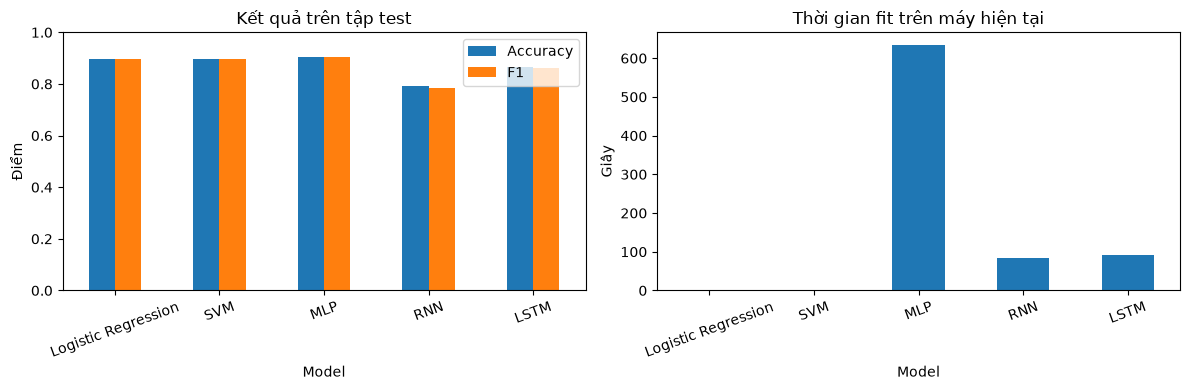

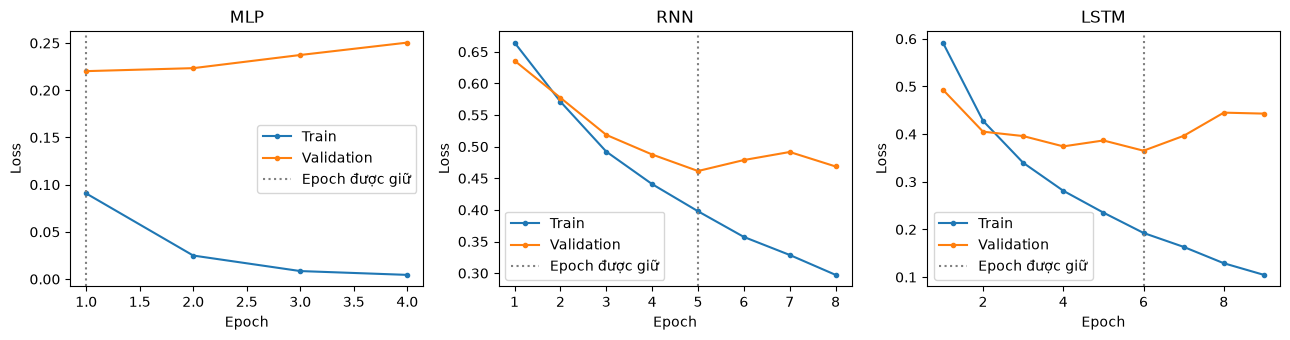

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results.set_index("Model")[["Accuracy", "F1"]].plot.bar(
    ax=axes[0], ylim=(0, 1), rot=20, title="Kết quả trên tập test"
)
axes[0].set_ylabel("Điểm")
results.set_index("Model")["Fit time (s)"].plot.bar(
    ax=axes[1], rot=20, title="Thời gian fit trên máy hiện tại"
)
axes[1].set_ylabel("Giây")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, name, history, best_epoch in zip(
    axes, ["MLP", "RNN", "LSTM"],
    [mlp_history, rnn_history, lstm_history],
    [mlp_best_epoch, rnn_best_epoch, lstm_best_epoch],
):
    epochs_run = range(1, len(history["val_loss"]) + 1)
    ax.plot(epochs_run, history["train_loss"], marker=".", label="Train")
    ax.plot(epochs_run, history["val_loss"], marker=".", label="Validation")
    ax.axvline(best_epoch, color="grey", linestyle=":", label="Epoch được giữ")
    ax.set(title=name, xlabel="Epoch", ylabel="Loss")
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Xem một vài dự đoán sai của LSTM

Lấy hai lỗi đầu tiên ở mỗi lớp theo thứ tự test.

In [14]:
label_names = {0: "Tiêu cực", 1: "Tích cực"}
for true_label in (0, 1):
    wrong = np.flatnonzero(
        (y_test == true_label) & (predictions["LSTM"] != y_test)
    )[:2]
    for index in wrong:
        visible_text = " ".join(tokenize(test_texts[index])[-MAX_LEN:])
        print(
            f"Review #{index}: thật={label_names[int(y_test[index])]}, "
            f"dự đoán={label_names[int(predictions['LSTM'][index])]}"
        )
        print(visible_text[:350] + ("..." if len(visible_text) > 350 else ""))
        print()

Review #4: thật=Tiêu cực, dự đoán=Tích cực
first off let me say if you haven't enjoyed a van damme movie since bloodsport you probably will not like this movie most of these movies may not have the best plots or best actors but i enjoy these kinds of movies for what they are this movie is much better than any of the movies the other action guys segal and dolph have thought about putting out...

Review #15: thật=Tiêu cực, dự đoán=Tích cực
now i love italian horror films the cheesier they are the better however this is not cheesy italian this is week old spaghetti sauce with rotting meatballs it is amateur hour on every level there is no suspense no horror with just a few drops of blood scattered around to remind you that you are in fact watching a horror film the special effects con...

Review #12505: thật=Tích cực, dự đoán=Tiêu cực
true but some other stuff is just way off the mark especially today delhi is complicated india is complicated the director tries to simplify both and fails 

## 10. Nhận xét (phụ thuộc vào từng lần chạy)

Trong lần chạy này, MLP đạt Accuracy khoảng **90,45%** và F1 **0,90**, cao nhất trong năm mô hình. SVM đạt 89,7%, còn Logistic Regression đạt 89,60%; hai mô hình tuyến tính khá gần nhau. MLP tăng khoảng 0,75 điểm phần trăm Accuracy so với SVM. 

LSTM đạt Accuracy **86,4%**, cao hơn RNN **79,1%** khoảng **7,3 điểm phần trăm**. F1 cũng tăng từ 0,78 lên 0,86. Hai mạng dùng cùng từ điển, độ dài chuỗi và kích thước lớp ẩn, nên kết quả này cho thấy LSTM hoạt động tốt hơn SimpleRNN với thiết lập đang thử. Khả năng giữ thông tin qua các bước thời gian của LSTM là một cách giải thích hợp lý, nhưng một lần chạy chưa đủ để kết luận cho mọi cấu hình.

Tăng giới hạn từ 5 lên 15 epoch giúp quan sát rõ việc học quá khớp. RNN chạy 8 epoch nhưng giữ epoch 5; LSTM chạy 9 epoch và giữ epoch 6. Sau các mốc này, train loss tiếp tục giảm còn validation loss có xu hướng tăng. MLP cũng gặp hiện tượng tương tự: train loss giảm từ 0,09 ở epoch 1 xuống 0,0045 ở epoch 4, trong khi validation loss tăng từ 0,22 lên 0,25.

Các mô hình TF-IDF đều có kết quả cao hơn hai mạng chuỗi trong thử nghiệm này. Một yếu tố cần tính đến là TF-IDF dùng cả review và tối đa 50.000 từ/cặp từ, còn RNN/LSTM chỉ giữ 200 từ cuối với từ điển 10.000 mục. Bài đang so sánh các cách xây dựng mô hình hoàn chỉnh, chưa tách riêng ảnh hưởng của kiến trúc và cách biểu diễn văn bản.

Ở ví dụ sai #15, review mở đầu bằng việc thích thể loại phim kinh dị Ý, rồi chuyển sang chê bộ phim với những cụm như 'no suspense' và 'no horror'. LSTM vẫn dự đoán tích cực. Ví dụ này cho thấy các câu khen/chê xen kẽ và đối tượng mà lời khen hướng tới có thể gây khó khăn. Đoạn trích của mẫu #12505 lại chứa nhiều lời chê dù nhãn toàn review là tích cực; cần đọc cả review để kiểm tra vai trò của ngữ cảnh và việc cắt chuỗi.

Kết quả còn giới hạn ở một seed và các siêu tham số đã chọn. Đặc biệt, chênh lệch rất nhỏ giữa SVM và Logistic Regression chưa đủ để khẳng định mô hình nào luôn tốt hơn.